# Employee Sentiment Analysis

**Goal:** assess employee sentiment and engagement from an unlabeled dataset of employee e-mails (`test.csv`).

| Task | What this notebook does | Supporting module |
|---|---|---|
| 1. Sentiment labeling | Label every message Positive / Negative / Neutral | `src/sentiment.py` |
| 2. EDA | Structure, distributions, trends, anomalies, charts | `src/eda.py`, `src/visualization.py` |
| 3. Employee score | Monthly score per employee (+1 / −1 / 0, resets monthly) | `src/scoring.py` |
| 4. Ranking | Top-3 positive and top-3 negative employees per month | `src/scoring.py` |
| 5. Flight risk | ≥ 4 negative messages within any rolling 30-day window | `src/flight_risk.py` |
| 6. Predictive model | scikit-learn linear regression of the monthly score | `src/modeling.py` |

All processing happens in this notebook; the `src/` modules only hold the reusable functions so that each step is short, testable (`tests/`) and reproducible (`python run_pipeline.py` produces the identical outputs from the raw CSV).

## 0. Setup

In [1]:
import json, warnings
import pandas as pd
from IPython.display import Image, Markdown, display
show = lambda text: display(Markdown(text))

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from src import config as C
from src import preprocessing, sentiment, eda, scoring, flight_risk, modeling, findings
from src import visualization as viz

print("Raw data      :", C.RAW_DATA_PATH)
print("Labeling with :", C.SENTIMENT_METHOD)

Raw data      : /home/claude/employee-sentiment-analysis/data/raw/test.csv
Labeling with : vader


## 1. Load and clean the data

The raw file has four columns: `Subject`, `body`, `date`, `from` (the employee). The bodies are Enron e-mails exported with
**quoted-printable artifacts** (`=20` = space, `=` + newline = soft line break, `=01)` = control byte). These are pure noise for an NLP model,
so `preprocessing.clean_text` decodes them, drops forwarded / quoted history, URLs and e-mail addresses, and collapses whitespace.
The original `body` is kept untouched for traceability; the model reads `clean_text` = subject + cleaned body.

In [2]:
raw = preprocessing.load_raw()
df = preprocessing.prepare(raw)
print(raw.shape)
raw.head()

(2191, 4)


,Subject,body,date,from
0,EnronOptions Update!,EnronOptions Announcement\n\n\nWe have updated...,2010-05-10,sally.beck@enron.com
1,(No Subject),"Marc,\n\nUnfortunately, today is not going to ...",2010-07-29,eric.bass@enron.com
2,Phone Screen Interview - Shannon L. Burnham,"When: Wednesday, June 06, 2001 10:00 AM-11:00 ...",2011-07-25,sally.beck@enron.com
3,RE: My new work email,we were thinking papasitos (we can meet somewh...,2010-03-25,johnny.palmer@enron.com
4,Bet,Since you never gave me the $20 for the last t...,2011-05-21,lydia.delgado@enron.com


In [3]:
# before / after cleaning for one message
i = df["body"].str.contains("=20").idxmax()
print("RAW  :", df.loc[i, "body"][:300].replace("\n", " | "))
print()
print("CLEAN:", df.loc[i, "clean_text"][:300])

RAW  : EnronOptions Announcement |  |  | We have updated the EnronOptions =01) Your Stock Option Program web site!  = | The=20 | web site now contains specific details of the EnronOptions Program includin= | g=20 | the December 29, 2000 grant price and additional information on employee=20 | eligibility. |  | Access EnronOpti

CLEAN: EnronOptions Update!. EnronOptions Announcement We have updated the EnronOptions ) Your Stock Option Program web site! The web site now contains specific details of the EnronOptions Program including the December 29, 2000 grant price and additional information on employee eligibility. Access EnronOp


## 2. Task 1 — Sentiment labeling

**Approach.** The brief prefers a large language model (LLM) or any suitable NLP technique. `src/sentiment.py` implements three interchangeable back-ends behind one function, selected with `SENTIMENT_METHOD` in `.env`:

| Back-end | When to use | Reproducibility |
|---|---|---|
| `llm` (Claude / GPT, zero-shot prompt, temperature 0) | Highest semantic accuracy: judges the sender's intent, not individual words | Every label cached in `data/llm_cache.csv`, so reruns need no API key |
| `vader` | Offline, no API key, no GPU | Fully deterministic |
| `transformer` (RoBERTa sentiment model) | Better context handling than a lexicon; needs `transformers` + `torch` | Deterministic |

**LLM labeling rule:** a fixed prompt (`sentiment.LLM_PROMPT`, printed below) defines the three classes:
- **Positive:** appreciation, enthusiasm, satisfaction, good news.
- **Negative:** frustration, complaints, criticism, worry, bad news, conflict.
- **Neutral:** purely informational or logistical content.

The reply is parsed to one label, and anything unparseable becomes Neutral.

**VADER labeling rule** (Hutto & Gilbert 2014): `compound ≥ 0.05 → Positive`, `compound ≤ −0.05 → Negative`, otherwise `Neutral`.

The method actually used is printed by the next cell.

In [4]:
print("Labeling method:", C.SENTIMENT_METHOD)
if C.SENTIMENT_METHOD == "llm":
    print(sentiment.LLM_PROMPT)

Labeling method: vader


In [5]:
df = sentiment.label_messages(df)          # adds `sentiment` and `sentiment_score_raw`
df = scoring.add_message_scores(df)        # +1 / -1 / 0 per message
df.drop(columns=["clean_body"]).to_csv(C.LABELED_PATH, index=False)
df[["from", "date", "Subject", "sentiment_score_raw", "sentiment"]].head(10)

,from,date,Subject,sentiment_score_raw,sentiment
0,johnny.palmer@enron.com,2010-01-01,ERCOT Readiness Update attached,0.4515,Positive
1,eric.bass@enron.com,2010-01-02,RE: data,0.3527,Positive
2,lydia.delgado@enron.com,2010-01-02,Re: Wellhead Accrual Income,0.4215,Positive
3,don.baughman@enron.com,2010-01-02,(No Subject),0.7998,Positive
4,lydia.delgado@enron.com,2010-01-02,Tiger recruiting #1,0.5719,Positive
5,eric.bass@enron.com,2010-01-02,Doorstep meeting 8/4 New time - 9:30 AM,0.6369,Positive
6,eric.bass@enron.com,2010-01-03,Re: Jordan's comments on Doorstep meeting,0.8007,Positive
7,kayne.coulter@enron.com,2010-01-03,RE: Trade,0.4983,Positive
8,don.baughman@enron.com,2010-01-03,Re: Happy Hour,0.3798,Positive
9,eric.bass@enron.com,2010-01-03,computer wallpaper- must have,0.5719,Positive


In [6]:
# sanity check: example messages of each class (strongest VADER scores, or a random sample for LLM labels)
for lab in ["Positive", "Negative", "Neutral"]:
    sub = df[df.sentiment == lab]
    if sub["sentiment_score_raw"].notna().any():
        sub = sub.sort_values("sentiment_score_raw", ascending=(lab == "Negative"))
    else:
        sub = sub.sample(min(3, len(sub)), random_state=0)
    print(f"--- {lab} examples ---")
    for t in sub["clean_text"].head(3):
        print("•", t[:180])

--- Positive examples ---
• Thanks for January 1, 2000. I wanted to extend my thanks in advance to all of you who will join me in the office on January 1, 2000. I appreciate your willingness to devote part of
• Happy Holidays from HighSchoolAlumni.com!. [IMAGE] Dear Don: Heading back home for the holidays? Wouldn't it be cool to get together with your old crew from high school while you'r
• Happy Holidays from HighSchoolAlumni.com!. [IMAGE] Dear Don: Heading back home for the holidays? Wouldn't it be cool to get together with your old crew from high school while you'r
--- Negative examples ---
• Taliban life. Let's look at their lifestyle: No premarital sex. No oral sex. Giving or receiving. Never. No booze. None. No TV. No cable TV. No Spice channel. No Playboy channel. N
• Julie's Trip. My daughter has reservations at Kingsway House, 71 Eardley Court. Can you see if anyone knows if this place is a disaster? She is going with a girlfriend that doesn't
• Holcomb's new address and telep

In [7]:
# Data-integrity validation after cleaning + labeling
assert len(df) == len(raw), "no message may be dropped"
assert df["sentiment"].isin(["Positive", "Negative", "Neutral"]).all(), "every message has a valid label"
assert df["sentiment"].notna().all() and df["date"].notna().all()
assert set(df["from"]) == set(raw["from"].str.strip().str.lower()), "employee set preserved"
print("Integrity checks passed:", len(df), "messages,", df["from"].nunique(), "employees, all labeled")

Integrity checks passed: 2191 messages, 10 employees, all labeled


### Observations
_Generated from the data by `src/findings.py`, so they stay correct for any labeling method._

In [8]:
show(findings.labeling_md(df))

* Labeling method: **VADER (lexicon + rule-based NLP model)**.
* 2,191 messages labeled: **1,573 Positive (71.8%)**, **445 Neutral (20.3%)**, **173 Negative (7.9%)**.
* The dominant class is **Positive**. The corpus is mostly routine business correspondence, so polite and informational messages far outnumber complaints.
* Known limitation of a lexicon model: it reads words, not intent. Some purely factual messages that contain words such as *risk*, *problem* or *warning* (e.g. automatic mailbox warnings) are labeled Negative. Setting `SENTIMENT_METHOD=llm` switches to an LLM labeler with no other code changes.
* 70 messages have an empty body. They are labeled from their subject line, which is why the subject is part of the analysed text.

## 3. Task 2 — Exploratory Data Analysis

### 3.1 Structure, data types and missing values

In [9]:
print(json.dumps(eda.overview(df, raw), indent=2))
eda.structure(raw)

{
  "records": 2191,
  "columns": [
    "Subject",
    "body",
    "date",
    "from"
  ],
  "duplicate_rows": 0,
  "employees": 10,
  "date_min": "2010-01-01",
  "date_max": "2011-12-31",
  "months": 24,
  "median_words": 27.0,
  "empty_bodies": 70
}


,dtype,non_null,missing,unique
Subject,str,2191,0,1251
body,str,2191,0,1539
date,str,2191,0,690
from,str,2191,0,10


### 3.2 Distribution of sentiment labels

,count,share
sentiment,,
Positive,1573,0.718
Neutral,445,0.203
Negative,173,0.079


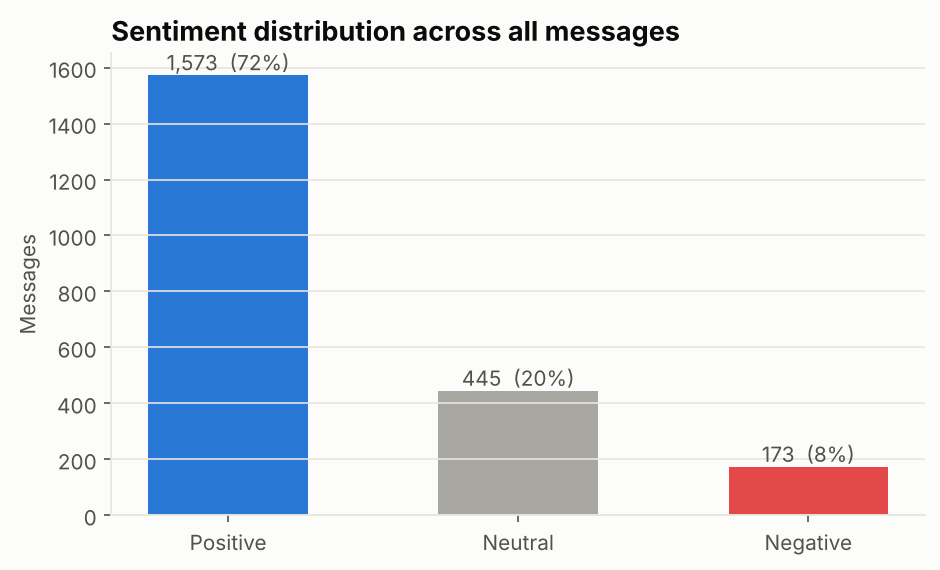

In [10]:
display(eda.sentiment_counts(df))
display(Image(viz.sentiment_distribution(df)))

### 3.3 Trends over time

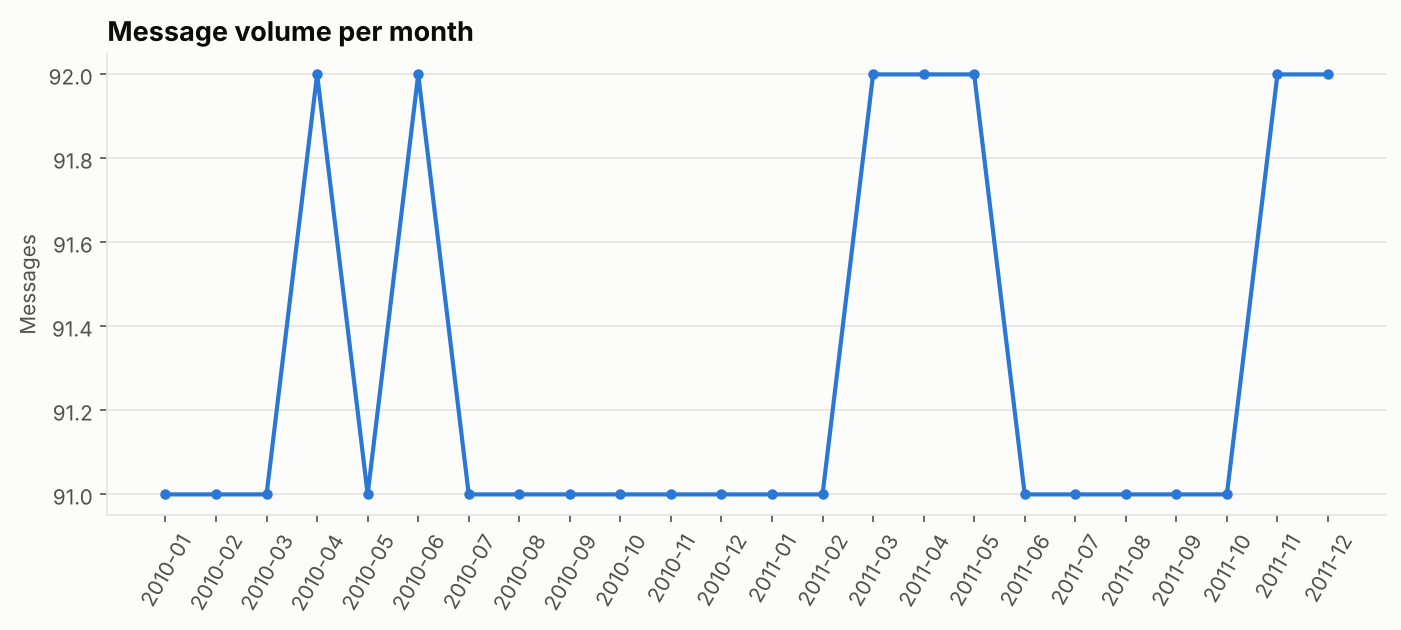

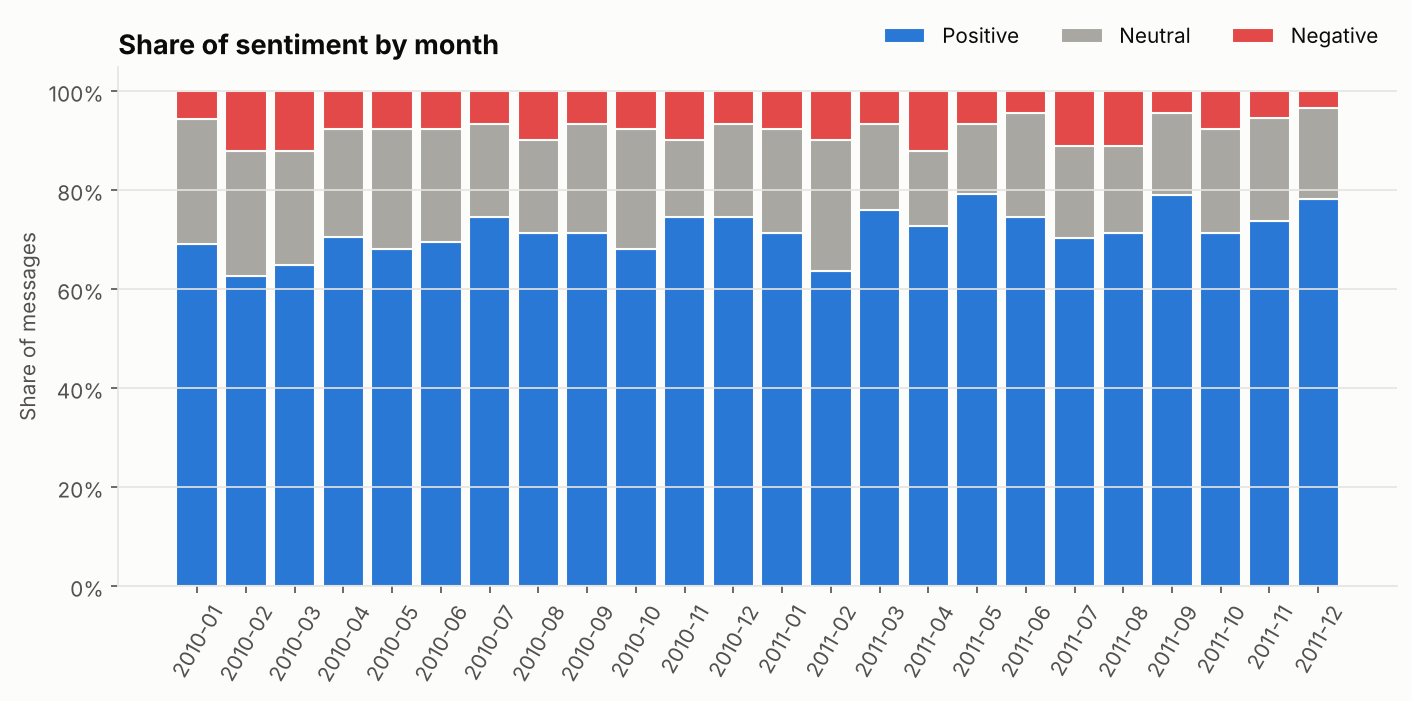

sentiment,Positive,Neutral,Negative,avg_score
year,,,,
2010,766,237,91,0.617
2011,807,208,82,0.661


In [11]:
display(Image(viz.messages_per_month(df)))
display(Image(viz.sentiment_over_time(df)))
eda.yearly_sentiment(df)

### 3.4 Employees, message length and weekly patterns

sentiment,Positive,Neutral,Negative,total,negative_share
from,,,,,
lydia.delgado@enron.com,203,65,16,284,0.056
john.arnold@enron.com,191,53,12,256,0.047
sally.beck@enron.com,159,43,25,227,0.110
patti.thompson@enron.com,167,38,20,225,0.089
bobette.riner@ipgdirect.com,149,45,23,217,0.106
don.baughman@enron.com,148,52,13,213,0.061
johnny.palmer@enron.com,151,41,21,213,0.099
eric.bass@enron.com,160,35,15,210,0.071
kayne.coulter@enron.com,123,33,18,174,0.103


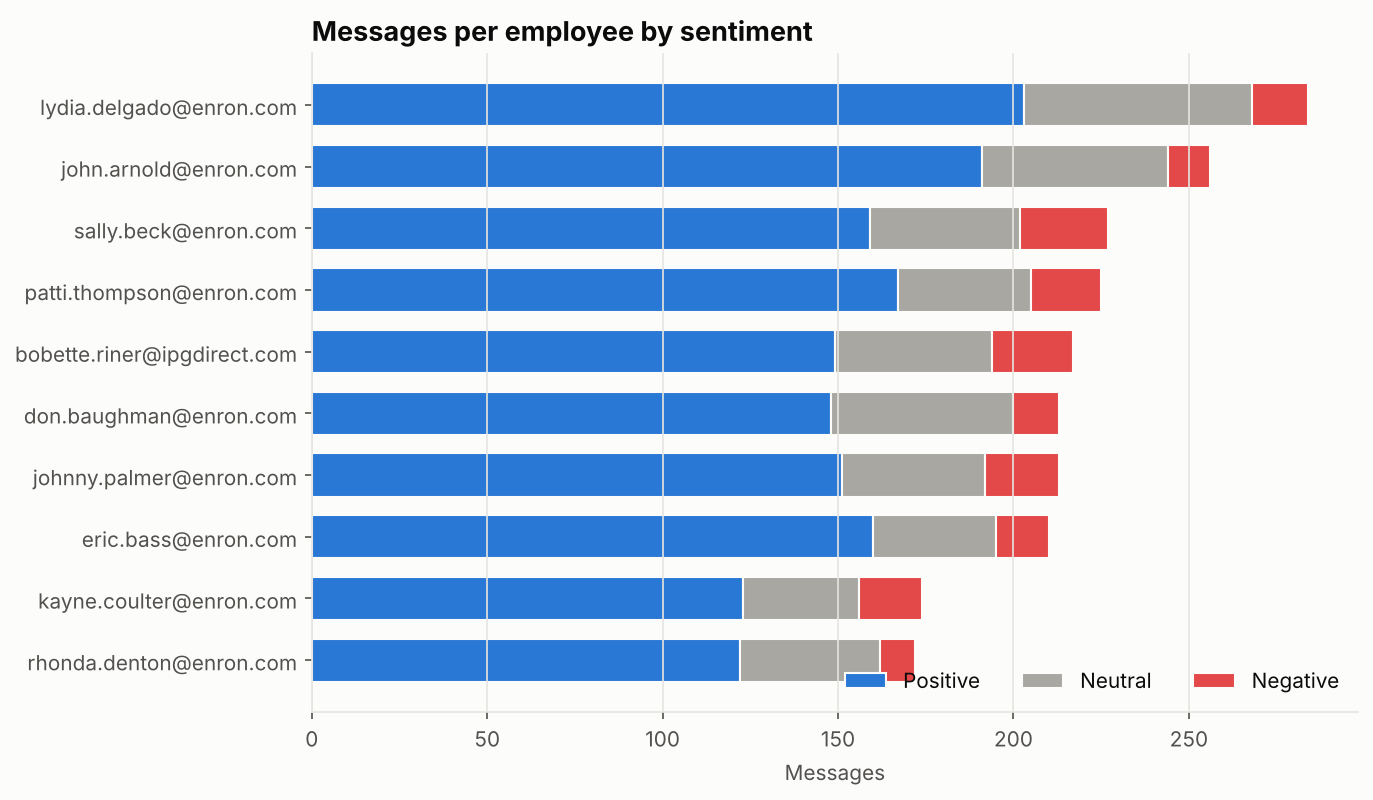

In [12]:
display(eda.per_employee(df))
display(Image(viz.messages_per_employee(df)))

,word_count,char_length
sentiment,,
Positive,35.0,205.0
Neutral,9.0,51.0
Negative,24.0,132.0


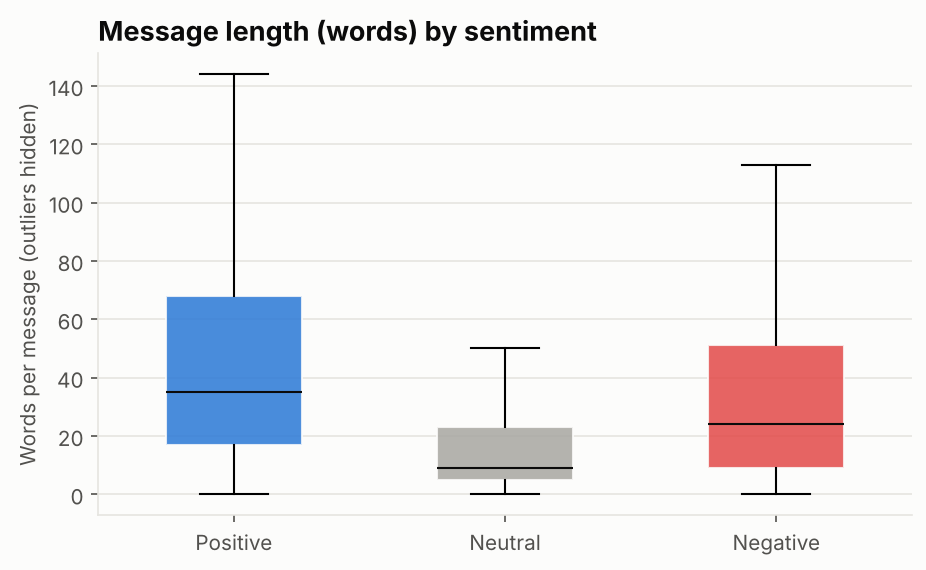

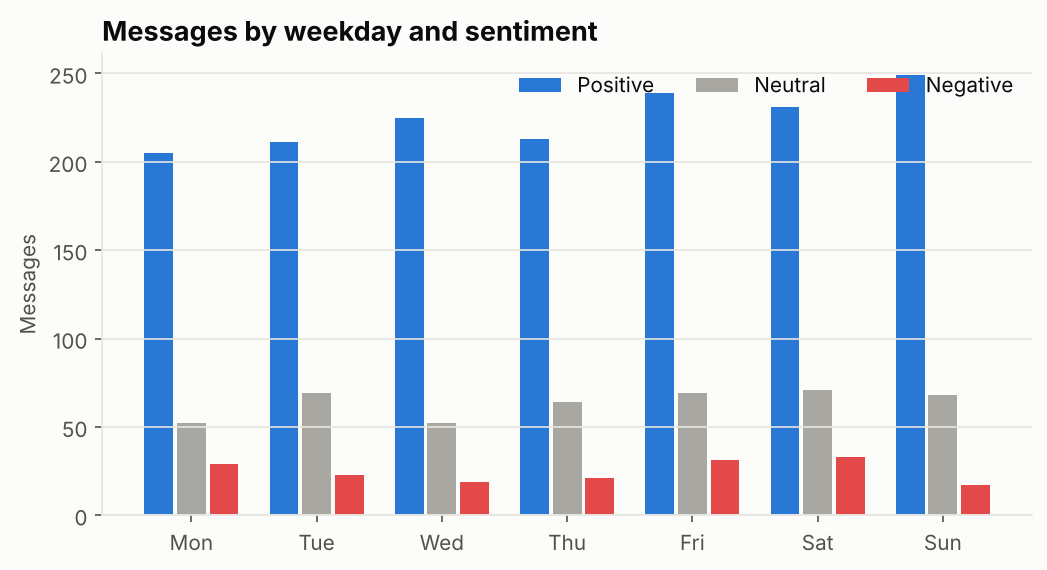

In [13]:
display(eda.length_stats(df))
display(Image(viz.length_by_sentiment(df)))
display(Image(viz.weekday_pattern(df)))

### EDA — key findings

In [14]:
show(findings.eda_md(df, raw))

* **Structure:** 2,191 rows × 4 columns (`Subject`, `body`, `date`, `from`); **no missing values**; 0 fully duplicated rows. `date` is parsed to datetime.
* **Coverage:** 10 employees, 24 months (2010-01-01 to 2011-12-31), and every employee is active in every month.
* **Anomaly:** Monthly volume is almost perfectly flat (91–92 messages per month); 30.5% of messages fall on weekends, about the same rate as weekdays. Real e-mail traffic is rarely this uniform, so the dates appear to have been **assigned synthetically**. Time-based conclusions should be read with caution.
* **Anomaly:** 625 messages repeat an earlier subject + body on a different date. They are kept because each row is a distinct sent message, but they inflate some employees' counts.
* **Trend:** the mean message score moves from 0.62 (2010) to 0.66 (2011).
* **Employees:** activity ranges from 172 (rhonda.denton@enron.com) to 284 messages (lydia.delgado@enron.com). Highest negative share: sally.beck@enron.com (11.0%), bobette.riner@ipgdirect.com (10.6%), kayne.coulter@enron.com (10.3%). Lowest: john.arnold@enron.com (4.7%).
* **Length:** Positive messages are the longest (median 35 words) and Neutral the shortest (median 9 words).

## 4. Task 3 — Monthly employee sentiment score

**Method.** Each message gets `Positive = +1`, `Negative = −1`, `Neutral = 0`. Messages are grouped by **(employee, calendar month)**,
where the month is the message date truncated to `YYYY-MM`, and the contributions are **summed**. Because every month is its own group,
the score starts from 0 at the beginning of each month (the required reset); nothing carries over. Months in which an employee sent no
messages simply have no row (the heatmap shows them as 0).

In [15]:
scores = scoring.monthly_scores(df)
scores.to_csv(C.MONTHLY_SCORES_PATH, index=False)
print(scores.shape)
display(scores.head(12))
scores["monthly_score"].describe()

(240, 7)


,employee,month,monthly_score,message_count,positive_count,negative_count,neutral_count
0,bobette.riner@ipgdirect.com,2010-01,1,2,1,0,1
1,don.baughman@enron.com,2010-01,8,9,8,0,1
2,eric.bass@enron.com,2010-01,9,10,9,0,1
3,john.arnold@enron.com,2010-01,5,7,5,0,2
4,johnny.palmer@enron.com,2010-01,3,6,4,1,1
5,kayne.coulter@enron.com,2010-01,14,22,14,0,8
6,lydia.delgado@enron.com,2010-01,9,13,10,1,2
7,patti.thompson@enron.com,2010-01,6,10,7,1,2
8,rhonda.denton@enron.com,2010-01,1,3,1,0,2
9,sally.beck@enron.com,2010-01,2,9,4,2,3


count    240.000000
mean       5.833333
std        3.989176
min       -1.000000
25%        3.000000
50%        5.500000
75%        8.000000
max       20.000000
Name: monthly_score, dtype: float64

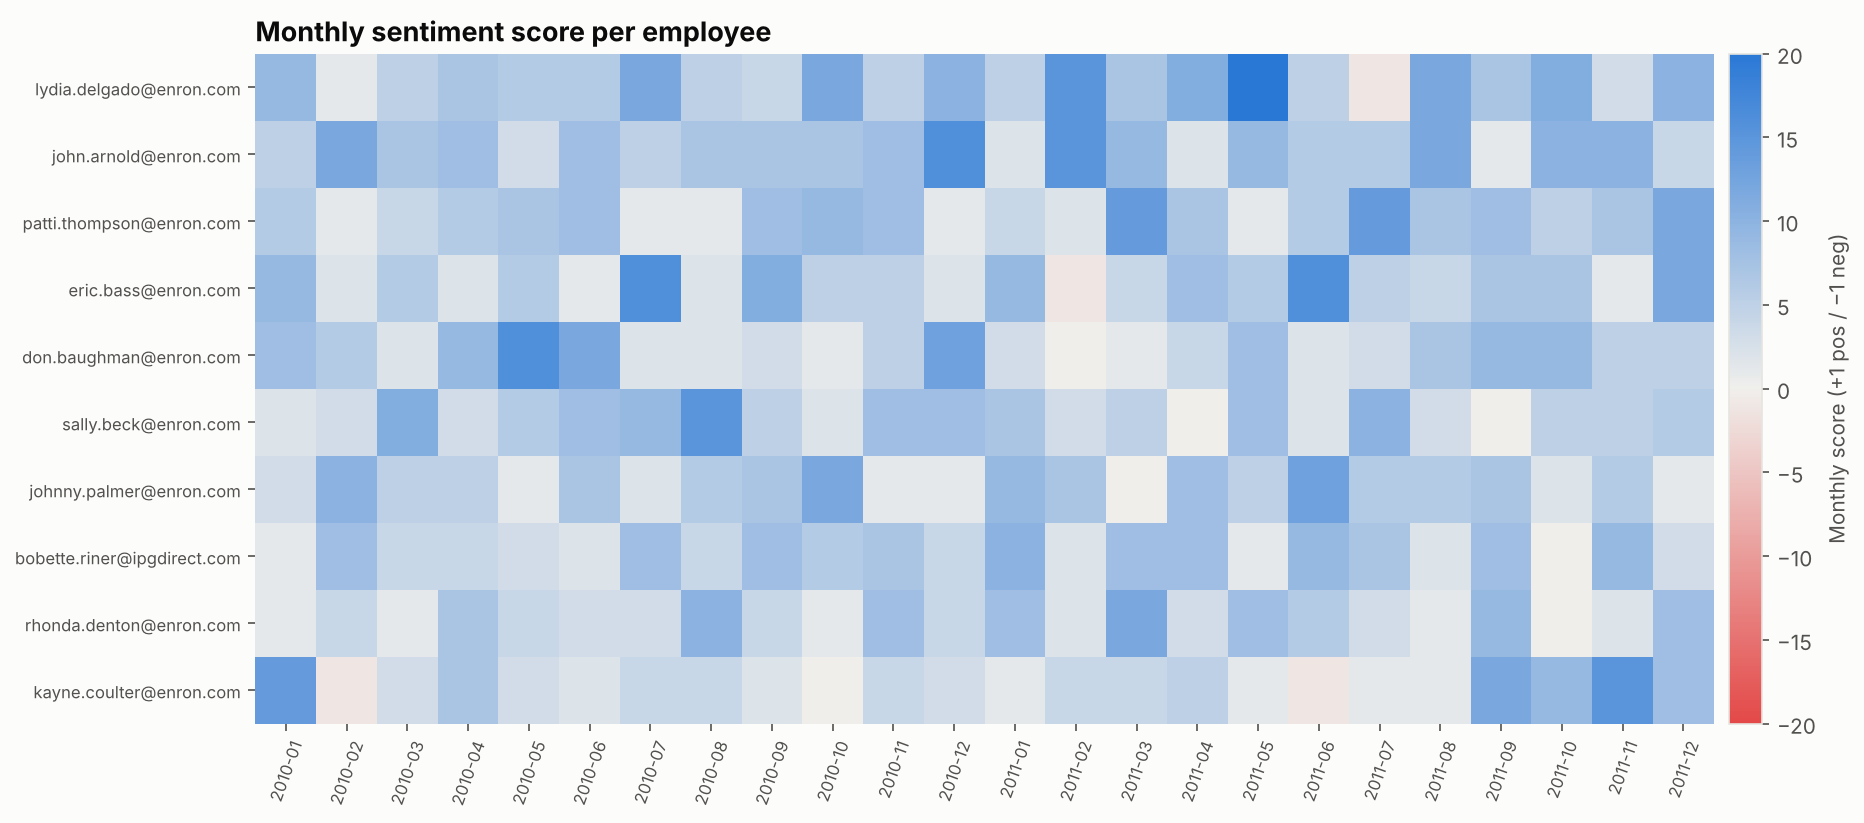

In [16]:
# validation: monthly scores must add up to the per-message total
assert scores["monthly_score"].sum() == df["message_score"].sum()
assert (scores["positive_count"] - scores["negative_count"] == scores["monthly_score"]).all()
display(Image(viz.score_heatmap(scores)))

### Observations

In [17]:
show(findings.scoring_md(scores))

* Monthly scores range from **-1 to 20** (mean 5.8, median 5.5).
* **11 of 240 employee-months are ≤ 0.** The most frequent is kayne.coulter@enron.com with 3 (2010-02, 2010-10, 2011-06).
* The validation asserts confirm that no message was lost or double-counted in the aggregation, and that score = positives − negatives in every month.

## 5. Task 4 — Employee ranking

**Method.** For each month, using the Task 3 scores:
* **Top 3 positive** — sort by `monthly_score` **descending**, then by employee name **alphabetically** to break ties.
* **Top 3 negative** — sort by `monthly_score` **ascending** (most negative first), then alphabetically.

In [18]:
rankings = scoring.monthly_rankings(scores)
rankings.to_csv(C.RANKINGS_PATH, index=False)

# wide, readable table: one row per month
wide = (rankings.assign(entry=lambda r: r.employee + " (" + r.monthly_score.astype(str) + ")")
        .pivot_table(index="month", columns=["list_type", "rank"], values="entry", aggfunc="first"))
wide

list_type                     Top Negative                                                                                        Top Positive  \
rank                                     1                                2                                3                                 1   
month                                                                                                                                            
2010-01    bobette.riner@ipgdirect.com (1)      rhonda.denton@enron.com (1)         sally.beck@enron.com (2)      kayne.coulter@enron.com (14)   
2010-02       kayne.coulter@enron.com (-1)      lydia.delgado@enron.com (1)     patti.thompson@enron.com (1)        john.arnold@enron.com (12)   
2010-03        rhonda.denton@enron.com (1)       don.baughman@enron.com (2)      kayne.coulter@enron.com (3)         sally.beck@enron.com (11)   
2010-04            eric.bass@enron.com (2)         sally.beck@enron.com (3)  bobette.riner@ipgdirect.com (4)        don.baughman@enron.com (9)   
2010-05        johnny.palmer@enron.com (1)  bobette.riner@ipgdirect.com (3)        john.arnold@enron.com (3)       don.baughman@enron.com (16)   
2010-06            eric.bass@enron.com (1)  bobette.riner@ipgdirect.com (2)      kayne.coulter@enron.com (2)       don.baughman@enron.com (12)   
2010-07       patti.thompson@enron.com (1)       don.baughman@enron.com (2)      johnny.palmer@enron.com (2)          eric.bass@enron.com (16)   
2010-08       patti.thompson@enron.com (1)       don.baughman@enron.com (2)          eric.bass@enron.com (2)         sally.beck@enron.com (15)   
2010-09        kayne.coulter@enron.com (2)       don.baughman@enron.com (3)      lydia.delgado@enron.com (4)          eric.bass@enron.com (11)   
2010-10        kayne.coulter@enron.com (0)       don.baughman@enron.com (1)      rhonda.denton@enron.com (1)      johnny.palmer@enron.com (12)   
2010-11        johnny.palmer@enron.com (1)      kayne.coulter@enron.com (4)       don.baughman@enron.com (5)         john.arnold@enron.com (8)   
2010-12        johnny.palmer@enron.com (1)     patti.thompson@enron.com (1)          eric.bass@enron.com (2)        john.arnold@enron.com (16)   
2011-01        kayne.coulter@enron.com (1)        john.arnold@enron.com (2)       don.baughman@enron.com (3)  bobette.riner@ipgdirect.com (10)   
2011-02           eric.bass@enron.com (-1)       don.baughman@enron.com (0)  bobette.riner@ipgdirect.com (2)        john.arnold@enron.com (15)   
2011-03        johnny.palmer@enron.com (0)       don.baughman@enron.com (1)          eric.bass@enron.com (4)     patti.thompson@enron.com (14)   
2011-04           sally.beck@enron.com (0)        john.arnold@enron.com (2)      rhonda.denton@enron.com (3)      lydia.delgado@enron.com (11)   
2011-05    bobette.riner@ipgdirect.com (1)      kayne.coulter@enron.com (1)     patti.thompson@enron.com (1)      lydia.delgado@enron.com (20)   
2011-06       kayne.coulter@enron.com (-1)       don.baughman@enron.com (2)         sally.beck@enron.com (2)          eric.bass@enron.com (16)   
2011-07       lydia.delgado@enron.com (-1)      kayne.coulter@enron.com (1)       don.baughman@enron.com (3)     patti.thompson@enron.com (14)   
2011-08        kayne.coulter@enron.com (1)      rhonda.denton@enron.com (1)  bobette.riner@ipgdirect.com (2)        john.arnold@enron.com (12)   
2011-09           sally.beck@enron.com (0)        john.arnold@enron.com (1)          eric.bass@enron.com (7)      kayne.coulter@enron.com (12)   
2011-10    bobette.riner@ipgdirect.com (0)      rhonda.denton@enron.com (0)      johnny.palmer@enron.com (2)      lydia.delgado@enron.com (11)   
2011-11            eric.bass@enron.com (1)      rhonda.denton@enron.com (2)      lydia.delgado@enron.com (3)      kayne.coulter@enron.com (15)   
2011-12        johnny.palmer@enron.com (1)  bobette.riner@ipgdirect.com (3)        john.arnold@enron.com (4)          eric.bass@enron.com (12)   

list_type                                                

Latest month: 2011-12


,employee,monthly_score
0,eric.bass@enron.com,12
1,patti.thompson@enron.com,12
2,lydia.delgado@enron.com,10


,employee,monthly_score
0,johnny.palmer@enron.com,1
1,bobette.riner@ipgdirect.com,3
2,john.arnold@enron.com,4


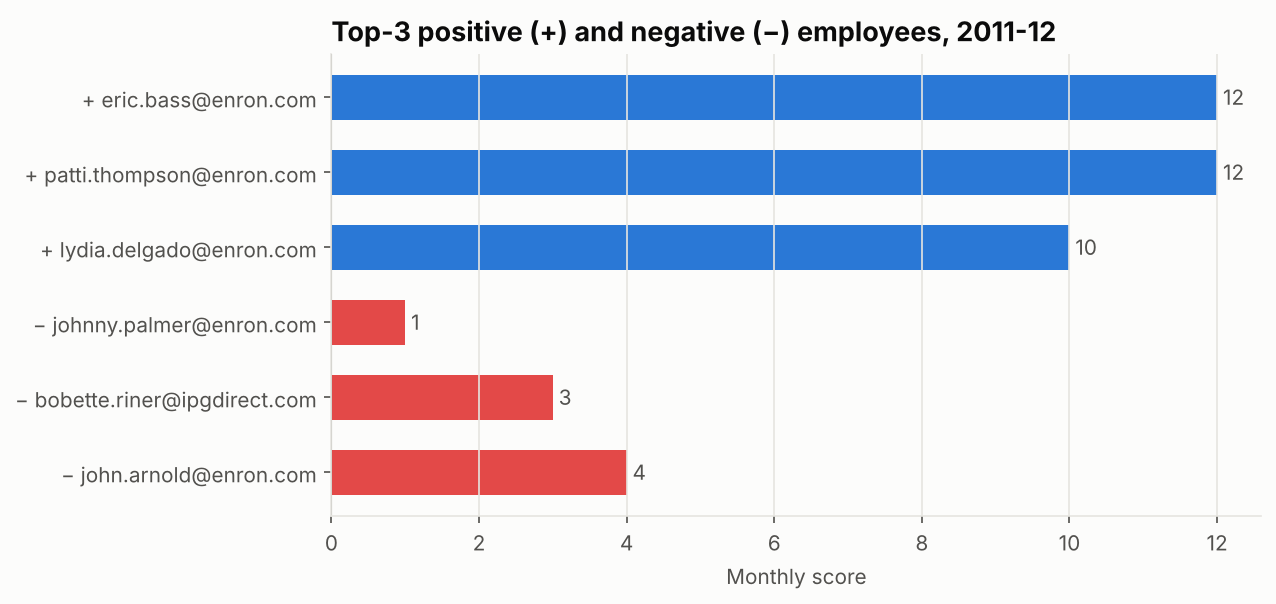

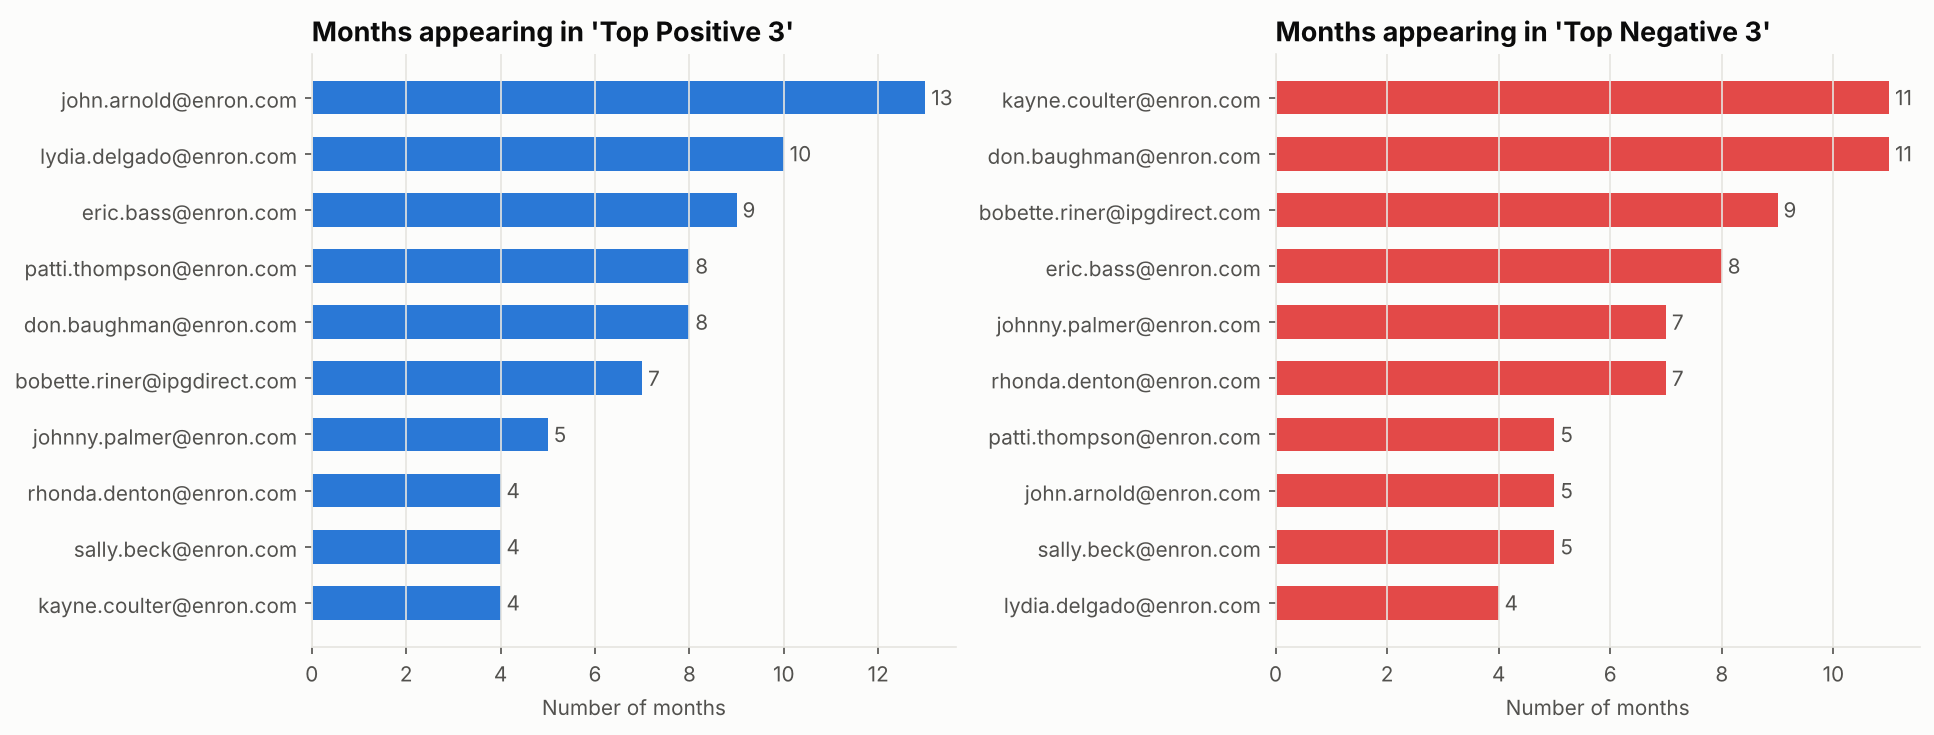

In [19]:
latest = sorted(scores.month.unique())[-1]
top_pos, top_neg = scoring.rank_month(scores, latest)
print("Latest month:", latest)
display(top_pos[["employee", "monthly_score"]].reset_index(drop=True))
display(top_neg[["employee", "monthly_score"]].reset_index(drop=True))
display(Image(viz.latest_month_ranking(scores, latest)))
display(Image(viz.ranking_frequency(rankings)))

In [20]:
# whole-period view: sum of all monthly scores
scoring.overall_ranking(scores)

,employee,total_score
0,lydia.delgado@enron.com,187
1,john.arnold@enron.com,179
2,patti.thompson@enron.com,147
3,eric.bass@enron.com,145
4,don.baughman@enron.com,135
5,sally.beck@enron.com,134
6,johnny.palmer@enron.com,130
7,bobette.riner@ipgdirect.com,126
8,rhonda.denton@enron.com,112
9,kayne.coulter@enron.com,105


### Observations

In [21]:
show(findings.ranking_md(scores, rankings))

* **Latest month (2011-12):** top positive: eric.bass@enron.com (12), patti.thompson@enron.com (12), lydia.delgado@enron.com (10). Top negative: johnny.palmer@enron.com (1), bobette.riner@ipgdirect.com (3), john.arnold@enron.com (4). Ties are broken alphabetically.
* **Consistency across 24 months:** john.arnold@enron.com is in the monthly top-3 positive most often (13 months). don.baughman@enron.com and kayne.coulter@enron.com appear in the top-3 negative most often (11 months).
* Rankings partly reflect volume: the score is a sum, so prolific writers rank higher. The whole-period leader is lydia.delgado@enron.com (+187).

## 6. Task 5 — Flight risk identification

**Definition (from the brief):** an employee is a flight risk if they sent **4 or more negative messages within any rolling 30-day period**,
regardless of calendar month and regardless of their score.

**Method.** For each employee, take the sorted dates of their Negative messages and slide a window: if any 4 consecutive negatives
fit inside one 30-day span (first and fourth at most 29 days apart, i.e. day *d* … day *d+29*), the employee is flagged. This catches
bursts that straddle a month boundary, which a per-month count would miss. The boundary is covered by unit tests in `tests/test_logic.py`.

In [22]:
windows = flight_risk.find_risk_windows(df)
risk = flight_risk.flight_risk_employees(df, windows)
windows.to_csv(C.FLIGHT_RISK_WINDOWS_PATH, index=False)
risk.to_csv(C.FLIGHT_RISK_PATH, index=False)
print(f"{len(risk)} employee(s) flagged as flight risk")
risk

7 employee(s) flagged as flight risk


,employee,max_negatives_in_30d,first_flagged_window_start,qualifying_windows,total_negative_messages
0,sally.beck@enron.com,5,2011-08-06,2,25
1,bobette.riner@ipgdirect.com,4,2011-03-26,1,23
2,eric.bass@enron.com,4,2011-04-22,2,15
3,john.arnold@enron.com,4,2010-05-25,1,12
4,johnny.palmer@enron.com,4,2010-02-09,2,21
5,kayne.coulter@enron.com,4,2010-04-06,1,18
6,patti.thompson@enron.com,4,2011-07-02,1,20


Calendar-month method would flag: 4
Only caught by the rolling window: ['bobette.riner@ipgdirect.com', 'john.arnold@enron.com', 'johnny.palmer@enron.com']


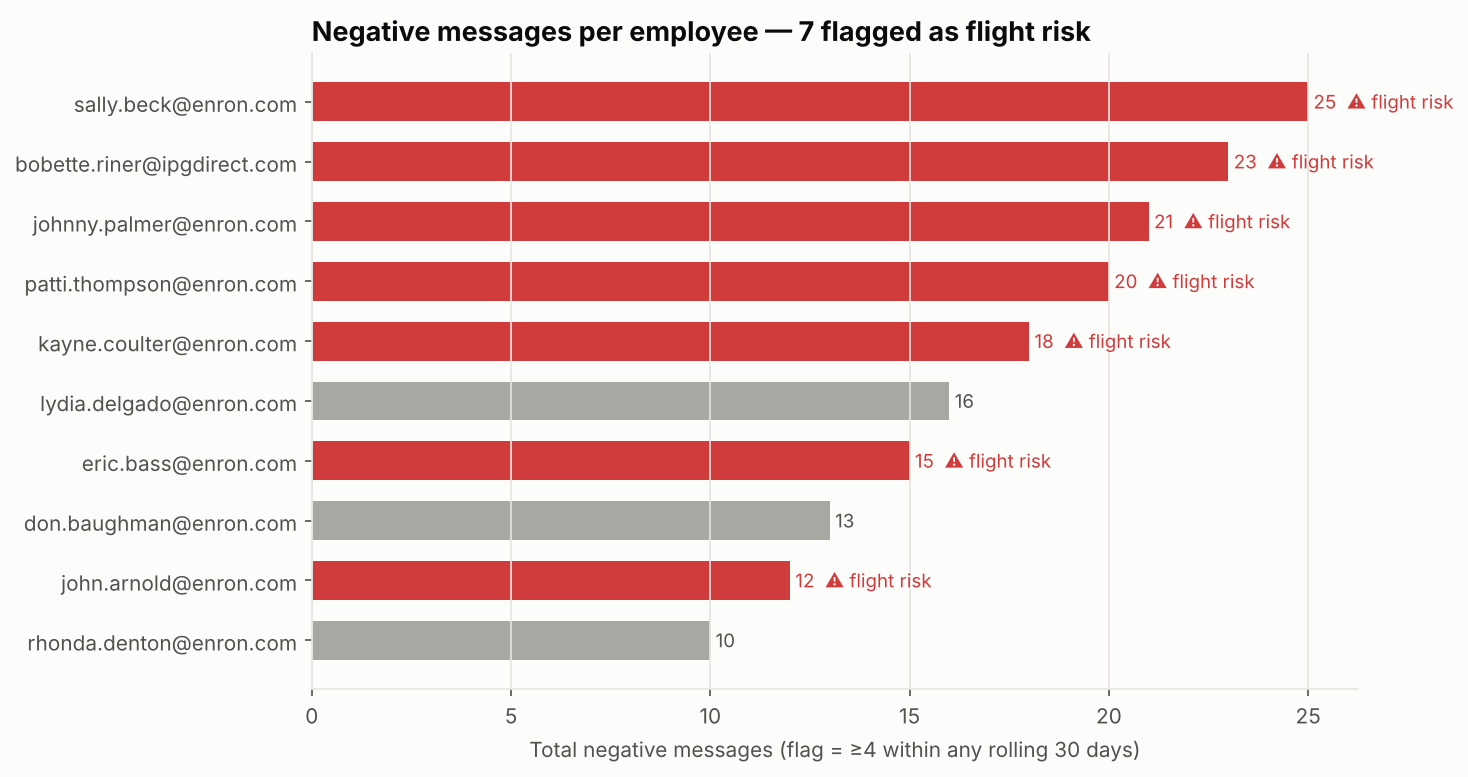

In [23]:
# robustness check: compare with a naive calendar-month count (>= 4 negatives in the same month)
naive = scores.loc[scores.negative_count >= 4, "employee"].unique()
print("Calendar-month method would flag:", len(naive))
print("Only caught by the rolling window:", sorted(set(risk.employee) - set(naive)))
display(Image(viz.flight_risk_chart(df, risk)))

### Observations

In [24]:
show(findings.flight_md(scores, risk, df['from'].nunique()))

* **7 of 10 employees are flagged** (max negatives in one 30-day window): sally.beck@enron.com (5), bobette.riner@ipgdirect.com (4), eric.bass@enron.com (4), john.arnold@enron.com (4), johnny.palmer@enron.com (4), kayne.coulter@enron.com (4), patti.thompson@enron.com (4).
* A calendar-month count would flag only **4**. The rolling window adds **bobette.riner@ipgdirect.com, john.arnold@enron.com and johnny.palmer@enron.com**, whose negative bursts straddle a month boundary. This is why the brief specifies a rolling window.
* The flag is deliberately independent of the score: an employee with a high long-run score can still have a short burst of negativity. Every qualifying window is listed in `data/processed/flight_risk_windows.csv` so that each flag can be reviewed manually.

## 7. Task 6 — Predictive modeling (linear regression)

**Target:** the monthly sentiment score of an employee (Task 3). **Unit:** one row per employee-month.

**Features** — chosen as behavioural signals that may influence sentiment and that are *not* computed from the sentiment labels (to avoid leakage):

| Feature | Rationale |
|---|---|
| `message_count` | engagement / activity level in the month |
| `avg_char_length`, `avg_word_count`, `total_words` | how much the employee writes |
| `active_days` | how many distinct days the employee communicated |
| `avg_exclamations`, `avg_questions` | emotional intensity / uncertainty |
| `prev_month_score` | sentiment momentum (last month's score, 0 if silent) |
| `month_index` | time trend |

**Model:** `StandardScaler → LinearRegression` (scikit-learn), 80/20 train/test split (`random_state=42`), 5-fold cross-validation,
compared against a mean-only baseline. Metrics: R², MAE, RMSE.

In [25]:
data = modeling.build_features(df, scores)
data[modeling.FEATURES + [modeling.TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
message_count,240.0,9.13,5.73,1.0,4.75,9.00,12.00,27.00
avg_char_length,240.0,231.76,100.44,0.0,170.48,224.04,275.26,706.00
avg_word_count,240.0,40.20,17.61,0.0,29.88,38.84,47.74,126.00
total_words,240.0,371.20,261.41,0.0,142.50,355.00,535.75,1211.00
active_days,240.0,7.52,4.25,1.0,4.00,7.00,11.00,20.00
avg_exclamations,240.0,0.20,0.24,0.0,0.00,0.14,0.29,1.54
avg_questions,240.0,0.93,1.92,0.0,0.08,0.25,0.54,16.65
prev_month_score,240.0,5.55,4.08,-1.0,2.00,5.00,8.00,20.00
month_index,240.0,11.50,6.94,0.0,5.75,11.50,17.25,23.00
monthly_score,240.0,5.83,3.99,-1.0,3.00,5.50,8.00,20.00


In [26]:
data[modeling.FEATURES + [modeling.TARGET]].corr()[modeling.TARGET].drop(modeling.TARGET).sort_values().round(3)

prev_month_score   -0.054
avg_word_count      0.077
month_index         0.079
avg_char_length     0.095
avg_exclamations    0.147
avg_questions       0.220
total_words         0.816
active_days         0.866
message_count       0.896
Name: monthly_score, dtype: float64

In [27]:
result = modeling.train_and_evaluate(data)
trend = modeling.company_trend(scores)
modeling.save_outputs(result, trend)
pd.Series(result["metrics"]).round(3)

n_rows                240.000
n_train               192.000
n_test                 48.000
train_r2                0.816
test_r2                 0.823
test_mae                1.373
test_rmse               1.787
baseline_test_mae       3.565
baseline_test_rmse      4.251
cv5_r2_mean             0.800
cv5_r2_std              0.033
intercept               5.854
dtype: float64

,feature,std_coefficient
0,message_count,4.115
1,total_words,-0.450
2,active_days,-0.385
3,avg_questions,0.375
4,prev_month_score,-0.310
5,avg_exclamations,0.289
6,month_index,0.256
7,avg_word_count,0.186
8,avg_char_length,-0.017


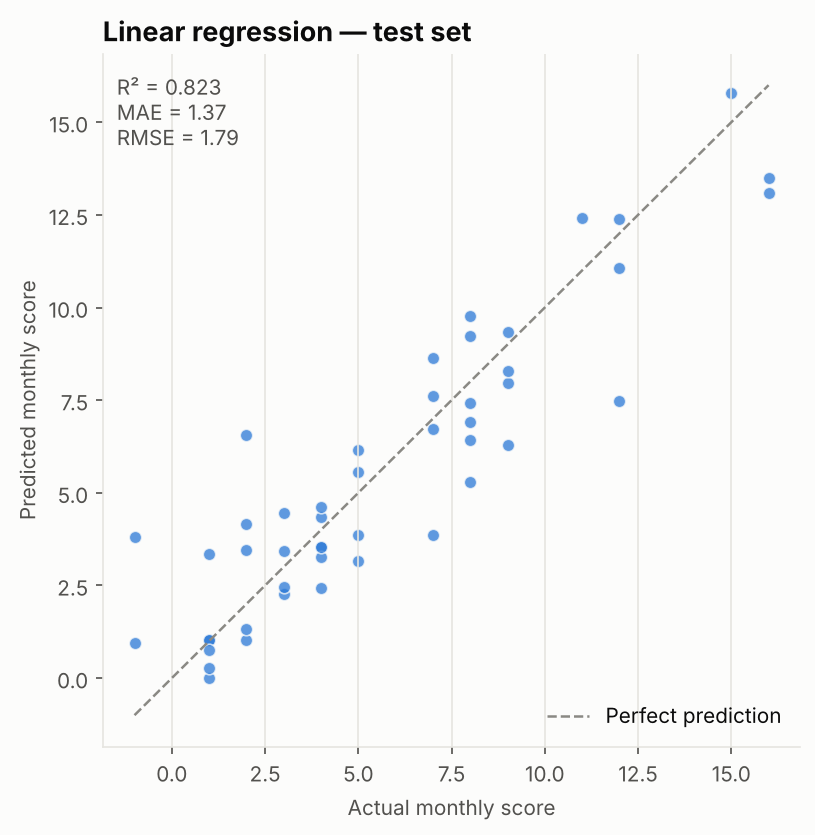

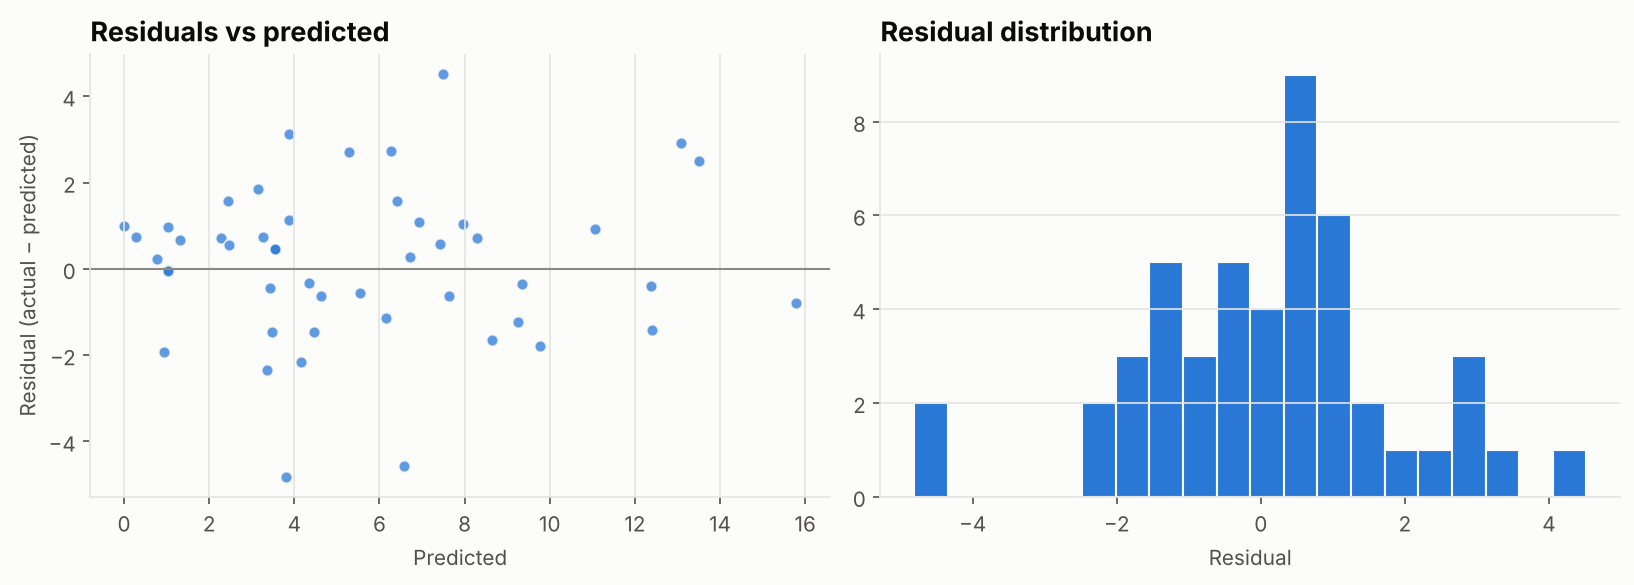

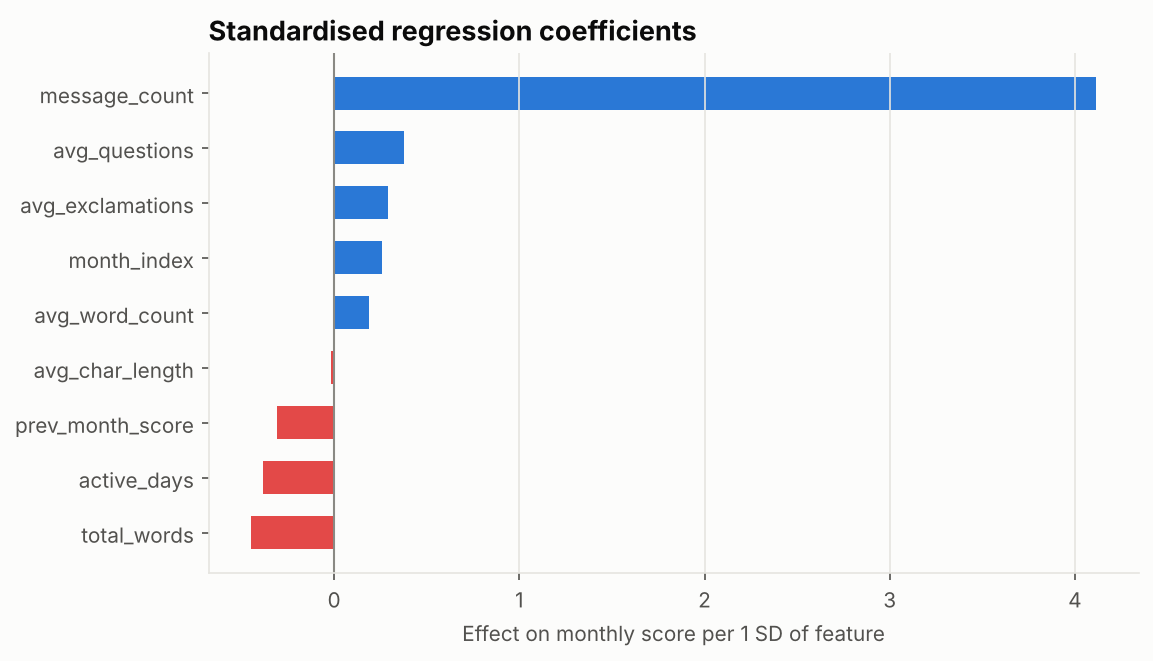

In [28]:
display(result["coefficients"].round(3))
display(Image(viz.model_pred_vs_actual(result["y_test"], result["y_pred"], result["metrics"])))
display(Image(viz.model_residuals(result["y_test"], result["y_pred"])))
display(Image(viz.model_coefficients(result["coefficients"])))

Company-wide trend: +0.0453 score points per month (R2=0.292)


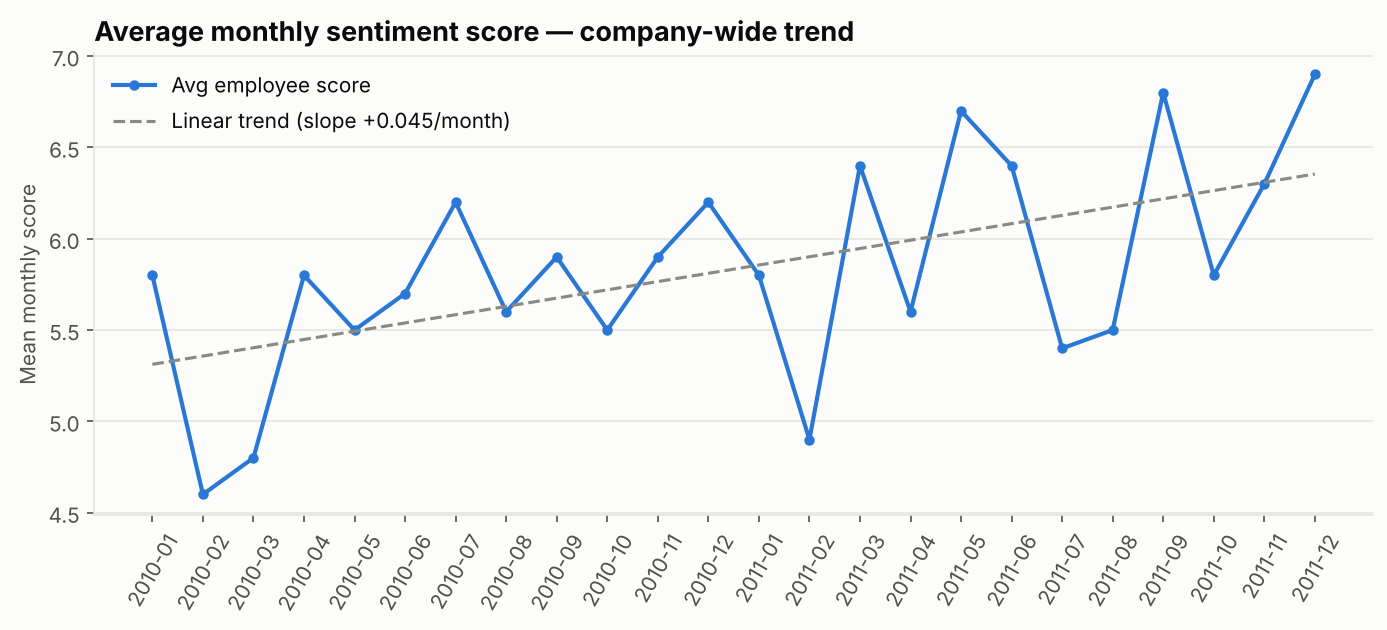

In [29]:
print(f"Company-wide trend: {trend['slope_per_month']:+.4f} score points per month (R2={trend['r2']:.3f})")
display(Image(viz.company_trend_chart(trend)))

### Model interpretation

In [30]:
show(findings.model_md(result['metrics'], result['coefficients'], trend, df))

* **Performance:** test R² = **0.82**, MAE = **1.37**, RMSE = **1.79**, against a mean-only baseline with MAE 3.57 / RMSE 4.25. 5-fold cross-validation R² = 0.80 ± 0.03. Train R² ≈ test R², so there is no sign of overfitting.
* **Strongest driver:** `message_count` (standardised coefficient +4.12).
  The average message scores +0.64, so every extra message moves the monthly score by about that much. The monthly score is largely a function of how much an employee communicates.
* `prev_month_score` is slightly negative (mild mean reversion); the company-wide average score trends +0.045 points per month.
* **Significance:** the model describes and forecasts the *level* of the score well. Because volume drives much of it, a volume-normalised target (average score per message) would better isolate tone, and is the natural next iteration.

## 8. Summary and recommendations
The same generated summary is written into `README.md` by `run_pipeline.py`.

In [31]:
summary_md = findings.readme_summary_md(df, raw, scores, rankings, risk, windows, result['metrics'], trend)
show(summary_md)

> Dataset: 2,191 messages · 10 employees · Jan 2010 – Dec 2011 (24 months). Labeling: VADER (lexicon + rule-based NLP model).

**Sentiment:** 1,573 Positive (71.8%) · 445 Neutral (20.3%) · 173 Negative (7.9%)

### Top three positive and negative employees (latest month, 2011-12)

| Rank | Top positive | Score | Top negative | Score |
|---|---|---|---|---|
| 1 | eric.bass@enron.com | 12 | johnny.palmer@enron.com | 1 |
| 2 | patti.thompson@enron.com | 12 | bobette.riner@ipgdirect.com | 3 |
| 3 | lydia.delgado@enron.com | 10 | john.arnold@enron.com | 4 |

Ties are broken alphabetically. Rankings for all months are in `data/processed/monthly_rankings.csv` and in the notebook. Across all 24 months, **john.arnold@enron.com** made the monthly top-3 positive most often (13 months), and **don.baughman@enron.com and kayne.coulter@enron.com** the top-3 negative most often (11 months).

### Employees flagged as flight risk (≥ 4 negative messages within any rolling 30 days)

| Employee | Max negatives in 30 days | First flagged window |
|---|---|---|
| sally.beck@enron.com | 5 | 2011-08-06 → 2011-09-04 |
| bobette.riner@ipgdirect.com | 4 | 2011-03-26 → 2011-04-24 |
| eric.bass@enron.com | 4 | 2011-04-22 → 2011-05-21 |
| john.arnold@enron.com | 4 | 2010-05-25 → 2010-06-23 |
| johnny.palmer@enron.com | 4 | 2010-02-09 → 2010-03-10 |
| kayne.coulter@enron.com | 4 | 2010-04-06 → 2010-05-05 |
| patti.thompson@enron.com | 4 | 2011-07-02 → 2011-07-31 |

A calendar-month count would catch only 4 of these 7. The rolling window also finds bobette.riner@ipgdirect.com, john.arnold@enron.com and johnny.palmer@enron.com, whose bursts of negativity cross a month boundary.

### Predictive model

Linear regression of the monthly score achieves **test R² = 0.82**, MAE = 1.37 and RMSE = 1.79. A mean-only baseline scores MAE = 3.57 and RMSE = 4.25. 5-fold cross-validation gives R² = 0.80 ± 0.03. The company-wide average score trends +0.045 points per month.

### Key insights and recommendations

1. Overall sentiment is healthy (71.8% positive). The risk signal comes from short **bursts** of negativity rather than persistently negative employees.
2. Prioritise check-ins with **sally.beck@enron.com** (strongest burst: 5 negatives in 30 days from 2011-08-06) and **don.baughman@enron.com and kayne.coulter@enron.com** (top-3 negative in 11 of 24 months).
3. Use the **rolling-window** flag operationally. It catches 3 employee(s) a monthly report would miss.
4. Monthly scores are volume-driven. Report the average score per message alongside the sum, so quiet employees are not mislabelled as disengaged.
5. Review each flagged window's messages before acting: automated sentiment is a screening tool, not a verdict.